# 04c. Explicabilité : pourquoi une province est à risque

Sentinelle Scolaire, défi 1.

Le notebook 04b a retenu, pour prévoir le taux d'abandon du primaire, un retour amorti vers le niveau habituel de chaque province. Ce notebook explique ce niveau, province par province, avec les modèles sauvegardés dans `data/04_analyse/modeles/` :

1. **effets chiffrés** (elastic net) : de combien de points le taux d'abandon change quand une variable change d'une unité ;
2. **facteurs de chaque province** (LightGBM après élimination récursive guidée par SHAP) : contribution de chaque variable au niveau de la province, en points de taux d'abandon ;
3. **alerte de rupture** : ce qui fait monter le score de rupture de chaque province.

Les liens décrits sont des **associations**, pas des causes : une variable associée à un fort abandon peut être le signe d'une situation (insécurité, pauvreté) plutôt que sa cause.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import json
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sentinelle.analyse import SORTIE_MODELES, SORTIE_MODELISATION, sauvegarde
from sentinelle.analyse.libelles import libelle

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})
SOURCE = "Source : annuaires DGESS, base apurée du défi 1. Calculs des auteurs."
lire = lambda nom: pd.read_csv(SORTIE_MODELISATION / f"{nom}.csv", sep=";", encoding="utf-8-sig")
modeles = {nom: sauvegarde.charger(SORTIE_MODELES, nom) for nom in ["ensemble", "sexe"]}

## 1. Les modèles sauvegardés

La fiche de chaque modèle (`fiche_modele.json`) décrit la cible, sa normalisation, le modèle de prévision retenu, les marges de l'intervalle, les variables de chaque volet et la qualité mesurée.

In [2]:
fiche = modeles["ensemble"]["fiche"]
print(json.dumps({k: fiche[k] for k in ["cible", "normalisation_cible"]}, ensure_ascii=False, indent=1))
print(json.dumps(fiche["explication"], ensure_ascii=False, indent=1))

{
 "cible": "taux d'abandon du primaire (%) entre t+h-1 et t+h, par province",
 "normalisation_cible": "z = logit(taux / 100), taux ramené dans [0,5 ; 99,5] ; dénormalisation : taux = 100 / (1 + exp(-z))"
}
{
 "effets_chiffres": {
  "modele": "elastic_net",
  "variables": [
   "part_cp1",
   "ni_ecole_ni_emploi_15_24_province",
   "hors_ecole_16_18_province",
   "part_etab_post_primaire_secondaire_publics_cantine_region",
   "deficit_places_pour_100_eleves_primaire"
  ],
  "r2_provinces_non_vues": 0.637
 },
 "facteurs_par_province": {
  "modele": "lightgbm (élimination récursive guidée par SHAP)",
  "variables": [
   "hors_ecole_16_18_province",
   "part_cp1",
   "eleves_par_maitre_primaire",
   "part_enseignantes_primaire",
   "parite_scolarisation_post_primaire_province",
   "chomage_25_64_province",
   "part_etab_post_primaire_secondaire_publics_cantine_region",
   "ni_ecole_ni_emploi_15_24_province"
  ],
  "r2_provinces_non_vues": 0.5224
 }
}


## 2. Effets chiffrés (elastic net)

Effet de chaque variable sur le niveau habituel d'abandon, dénormalisé : en points de taux pour un point de pourcentage (parts) ou une unité de la variable, et pour un écart-type (pour comparer les variables entre elles).

In [3]:
lire("explication_effets_lineaires_ensemble")

,variable,libelle,effet_pour_un_ecart_type_points,ecart_type_de_la_variable,unite,effet_par_unite_points
0,part_cp1,poids du CP1,3.220,0.0331,point de pourcentage,0.9717
1,ni_ecole_ni_emploi_15_24_province,jeunes ni à l'école ni en emploi,0.958,12.2366,unité de la variable,0.0783
2,deficit_places_pour_100_eleves_primaire,déficit de places assises,0.701,4.4759,unité de la variable,0.1565


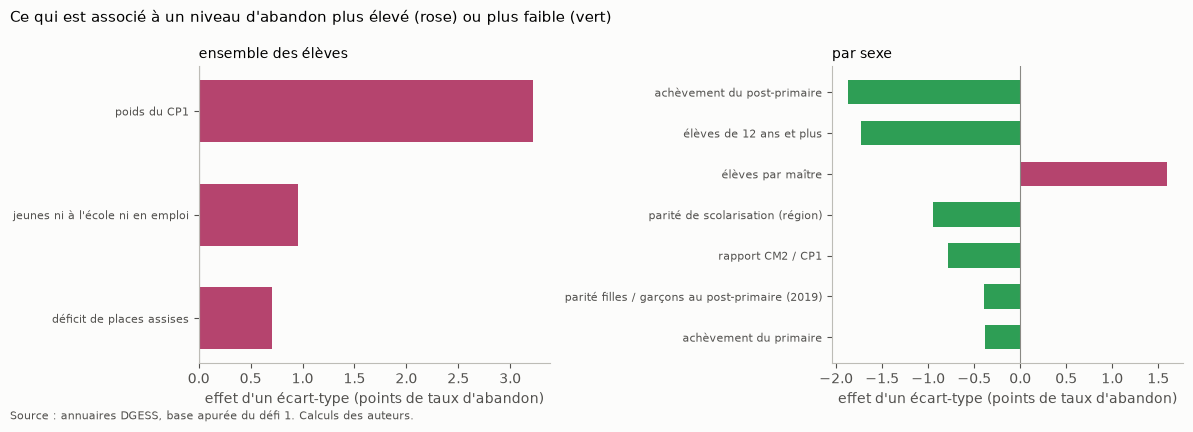

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, nom, titre in zip(axes, ["ensemble", "sexe"], ["ensemble des élèves", "par sexe"]):
    e = lire(f"explication_effets_lineaires_{nom}").iloc[::-1]
    couleur = np.where(e["effet_pour_un_ecart_type_points"] > 0, "#b5446e", "#2e9e55")
    ax.barh(e["libelle"], e["effet_pour_un_ecart_type_points"], color=couleur, height=0.6)
    ax.axvline(0, color="#8a8984", lw=0.8)
    ax.set_xlabel("effet d'un écart-type (points de taux d'abandon)")
    ax.set_title(titre, loc="left", fontsize=10); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Ce qui est associé à un niveau d'abandon plus élevé (rose) ou plus faible (vert)", x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 3. Facteurs de chaque province : vue d'ensemble (SHAP)

Chaque point est une province. Sa position dit de combien de points la variable pousse son niveau d'abandon vers le haut (à droite) ou vers le bas (à gauche) ; sa couleur dit si la valeur de la variable est élevée (rouge) ou faible (bleu) dans cette province.

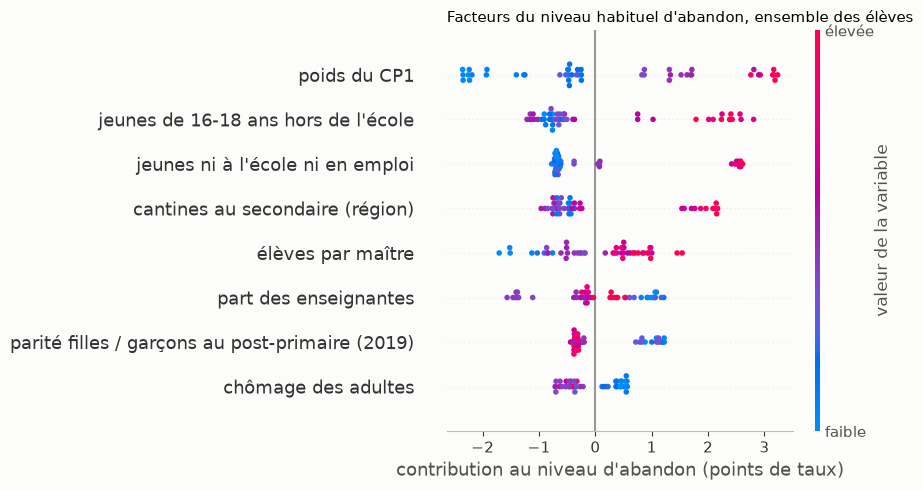

In [5]:
def explication(nom):
    contrib = lire(f"explication_contributions_{nom}")
    valeurs = lire(f"explication_valeurs_{nom}")
    variables = modeles[nom]["explication_lightgbm"]["variables"]
    base = float(lire(f"explication_valeur_de_base_{nom}").iloc[0, 0])
    e = shap.Explanation(values=contrib[variables].values, base_values=np.full(len(contrib), base),
                         data=valeurs[variables].values, feature_names=[libelle(v) for v in variables])
    return e, valeurs

exp_ens, valeurs_ens = explication("ensemble")
shap.plots.beeswarm(exp_ens, max_display=10, show=False)
plt.title("Facteurs du niveau habituel d'abandon, ensemble des élèves", loc="left", fontsize=11)
plt.gca().set_xlabel("contribution au niveau d'abandon (points de taux)")
for a in plt.gcf().axes[1:]:
    a.set_ylabel("valeur de la variable"); a.set_yticklabels(["faible", "élevée"])
plt.gcf().set_size_inches(9, 5); plt.tight_layout(); plt.show()

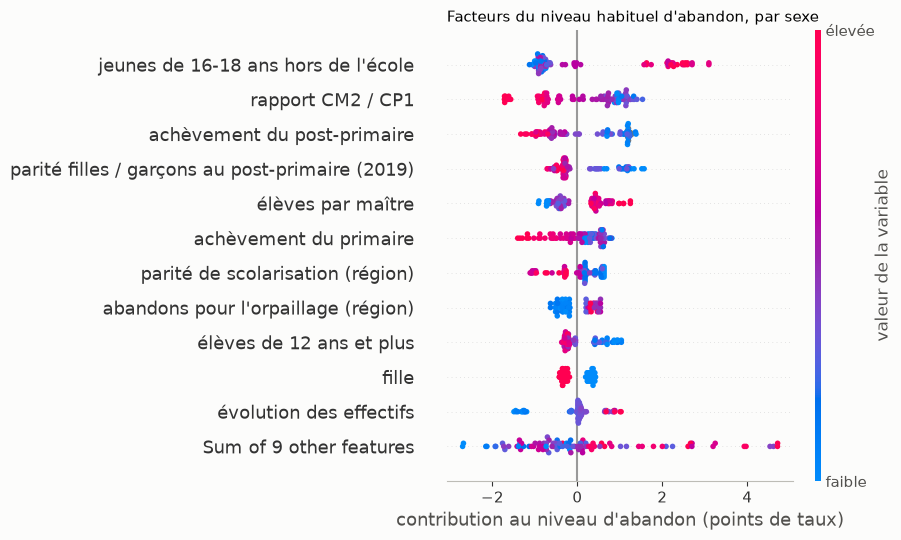

In [6]:
exp_sexe, valeurs_sexe = explication("sexe")
shap.plots.beeswarm(exp_sexe, max_display=12, show=False)
plt.title("Facteurs du niveau habituel d'abandon, par sexe", loc="left", fontsize=11)
plt.gca().set_xlabel("contribution au niveau d'abandon (points de taux)")
for a in plt.gcf().axes[1:]:
    a.set_ylabel("valeur de la variable"); a.set_yticklabels(["faible", "élevée"])
plt.gcf().set_size_inches(9, 5.5); plt.tight_layout(); plt.show()

## 4. Forme des liens

Pour les trois variables les plus importantes : contribution SHAP selon la valeur de la variable. Un lien en escalier ou en coude indique un seuil au-delà duquel le risque monte.

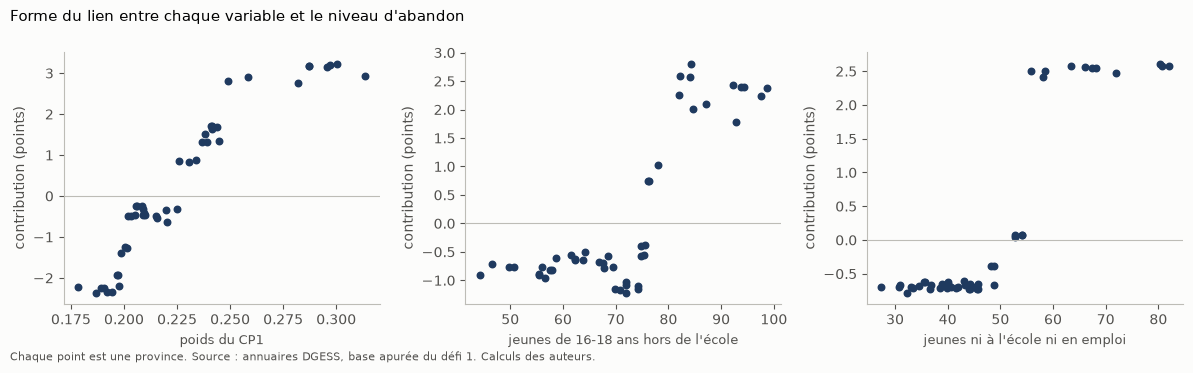

In [7]:
imp = lire("explication_importance_ensemble").head(3)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
contrib = lire("explication_contributions_ensemble")
for ax, (_, r) in zip(axes, imp.iterrows()):
    ax.scatter(valeurs_ens[r["variable"]], contrib[r["variable"]], color="#1f3a5f", s=22)
    ax.axhline(0, color="#bdbcb6", lw=0.8)
    ax.set_xlabel(r["libelle"], fontsize=9); ax.set_ylabel("contribution (points)")
fig.suptitle("Forme du lien entre chaque variable et le niveau d'abandon", x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.005, "Chaque point est une province. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 5. Une province en détail

Décomposition du niveau d'abandon expliqué de la province au taux prévu le plus élevé : on part de la moyenne des provinces (valeur de base) et chaque variable ajoute ou retire des points.

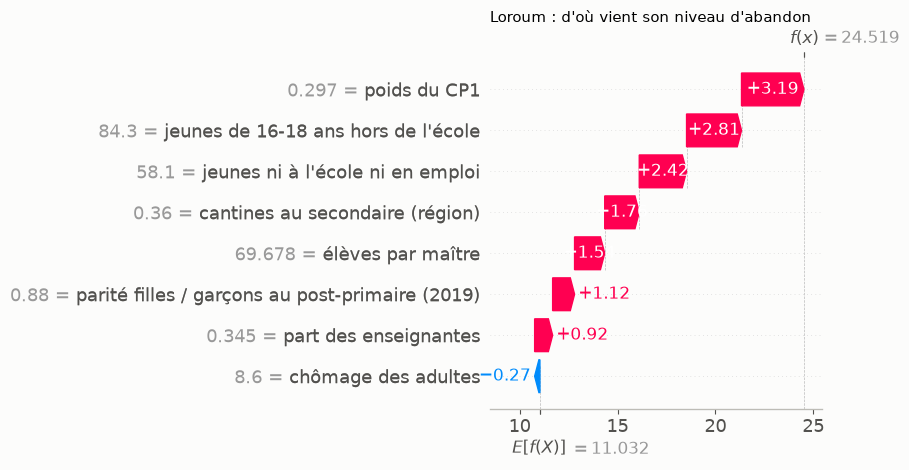

In [8]:
tableau = lire("tableau_de_bord_ensemble")
province = tableau.iloc[0]["province_nom"]
i = valeurs_ens.index[valeurs_ens["province_nom"] == province][0]
shap.plots.waterfall(exp_ens[i], max_display=9, show=False)
plt.title(f"{province} : d'où vient son niveau d'abandon", loc="left", fontsize=11)
plt.gcf().set_size_inches(9, 4.8); plt.tight_layout(); plt.show()

## 6. Filles et garçons d'une même province

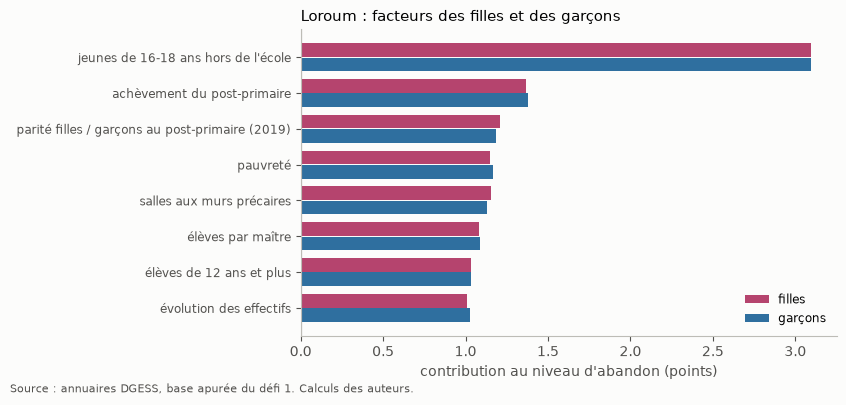

In [9]:
lignes = valeurs_sexe.index[valeurs_sexe["province_nom"] == province]
contrib_s = lire("explication_contributions_sexe").loc[lignes]
variables_s = modeles["sexe"]["explication_lightgbm"]["variables"]
comparaison = contrib_s.set_index("sexe")[variables_s].T
comparaison.index = [libelle(v) for v in comparaison.index]
comparaison = comparaison.reindex(comparaison.abs().max(axis=1).sort_values().index).tail(8)
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(comparaison))
ax.barh(y + 0.2, comparaison["F"], height=0.38, color="#b5446e", label="filles")
ax.barh(y - 0.2, comparaison["G"], height=0.38, color="#2f6f9f", label="garçons")
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set_yticks(y, comparaison.index, fontsize=8.5)
ax.set_xlabel("contribution au niveau d'abandon (points)")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title(f"{province} : facteurs des filles et des garçons", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 7. L'alerte de rupture : ce qui fait monter le score

Contribution de chaque signal au score de rupture (échelle logit) des dix provinces les plus exposées : coefficient de la régression × valeur normalisée du signal.

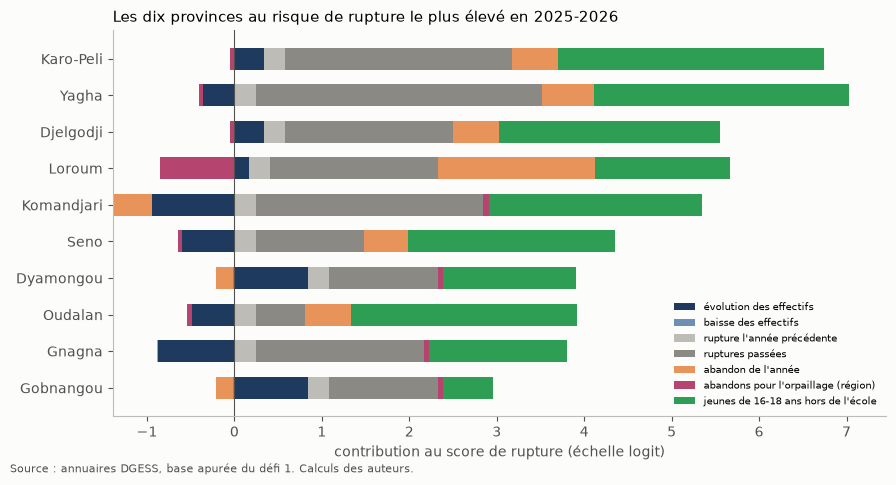

In [10]:
c = lire("contributions_alerte_rupture")
alerte = lire("alerte_rupture").head(10)
c = c.set_index("province_nom").loc[alerte["province_nom"]].drop(columns="constante").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
couleurs = ["#1f3a5f", "#6c8fb3", "#bdbcb6", "#8a8984", "#e8935a", "#b5446e", "#2e9e55"]
gauche_pos, gauche_neg = np.zeros(len(c)), np.zeros(len(c))
for colonne, couleur in zip(c.columns, couleurs):
    v = c[colonne].values
    ax.barh(c.index, np.where(v > 0, v, 0), left=gauche_pos, color=couleur, label=colonne, height=0.6)
    ax.barh(c.index, np.where(v < 0, v, 0), left=gauche_neg, color=couleur, height=0.6)
    gauche_pos += np.where(v > 0, v, 0); gauche_neg += np.where(v < 0, v, 0)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("contribution au score de rupture (échelle logit)")
ax.legend(frameon=False, fontsize=7.5, loc="lower right")
ax.set_title("Les dix provinces au risque de rupture le plus élevé en 2025-2026", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 8. Une phrase par province

Pour le tableau de bord et les fiches régionales, chaque province reçoit une phrase lisible par un décideur, construite à partir de la prévision, de l'intervalle, des facteurs et de l'alerte.

In [11]:
def phrase(r):
    facteurs = [str(r[f"facteur_{k}"]).split(" (")[0] for k in (1, 2, 3) if isinstance(r.get(f"facteur_{k}"), str)
                and not r[f"facteur_{k}"].startswith("aucun")]
    texte = (f"{r['province_nom']} ({r['region_nom']}) : taux d'abandon du primaire prévu à {r['taux_abandon_prevu']:.1f} % "
             f"en 2025-2026 (entre {r['borne_basse_80']:.1f} et {r['borne_haute_80']:.1f} % dans 8 cas sur 10), "
             f"risque {r['classe_de_risque']}.")
    if facteurs:
        texte += " Principaux facteurs : " + ", ".join(facteurs) + "."
    if r["risque_de_rupture"] == "élevé":
        texte += " Alerte : risque élevé de rupture de la scolarisation."
    return texte

for _, r in tableau.head(5).iterrows():
    print(phrase(r)); print()

Loroum (Yaadga) : taux d'abandon du primaire prévu à 27.1 % en 2025-2026 (entre 13.1 et 47.8 % dans 8 cas sur 10), risque élevé. Principaux facteurs : poids du CP1, jeunes de 16-18 ans hors de l'école, jeunes ni à l'école ni en emploi. Alerte : risque élevé de rupture de la scolarisation.

Karo-Peli (Soum) : taux d'abandon du primaire prévu à 23.6 % en 2025-2026 (entre 11.1 et 43.1 % dans 8 cas sur 10), risque élevé. Principaux facteurs : poids du CP1, jeunes ni à l'école ni en emploi, jeunes de 16-18 ans hors de l'école. Alerte : risque élevé de rupture de la scolarisation.

Djelgodji (Soum) : taux d'abandon du primaire prévu à 23.2 % en 2025-2026 (entre 10.9 et 42.6 % dans 8 cas sur 10), risque élevé. Principaux facteurs : poids du CP1, jeunes ni à l'école ni en emploi, jeunes de 16-18 ans hors de l'école. Alerte : risque élevé de rupture de la scolarisation.

Seno (Liptako) : taux d'abandon du primaire prévu à 23.0 % en 2025-2026 (entre 10.8 et 42.4 % dans 8 cas sur 10), risque élev

## Ce qu'il faut retenir

- **Trois signaux reviennent dans les provinces à fort abandon** : un CP1 lourd par rapport aux autres classes (les élèves se perdent au fil du cycle), beaucoup de jeunes hors de l'école ou sans emploi, et un déficit de places assises.
- **Par sexe**, s'y ajoutent l'achèvement du post-primaire, la parité filles / garçons et l'orpaillage : les mêmes provinces, mais pas tout à fait les mêmes leviers pour les filles et pour les garçons.
- **L'alerte de rupture** monte surtout avec la part de jeunes hors de l'école, l'abandon de l'année et la chute des effectifs.
- Ces explications sont des associations mesurées sur 43 provinces ; elles orientent l'action, elles ne prouvent pas un effet.